# Denoising: linear priors, bottlenecks and residual learning
        Twenty-five epochs, three training seeds and 10,000 official test digits.
        [Protocols](../docs/11_image_restoration.md) explain units, clipping, selection and shift.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
m = evidence('denoising')
pd.DataFrame([{'model':r['model'],'seed':r.get('seed'),'psnr':r['psnr']['mean'],
              'ssim':r['ssim']['mean']} for r in m['rows'] if r.get('sigma_255')==30])

,model,seed,psnr,ssim
0,noisy,NaN,21.272065,0.606696
1,pca_projection,NaN,23.398715,0.728525
2,pca_wiener,NaN,23.207506,0.746606
3,autoencoder,0.0,26.017159,0.959584
4,residual_denoiser,0.0,29.828367,0.981416
5,autoencoder,1.0,26.160306,0.959750
6,residual_denoiser,1.0,29.863793,0.980792
7,autoencoder,2.0,26.272803,0.961114
8,residual_denoiser,2.0,29.860607,0.981999


## Gaussian coefficient shrinkage
        For PCA coefficients with prior variance λ and isotropic noise variance σ²,
        the posterior-mean multiplier is λ/(λ+σ²). This shrinks weak directions most,
        but optimality depends on the prior. Ordinary projection can win on non-Gaussian digits.

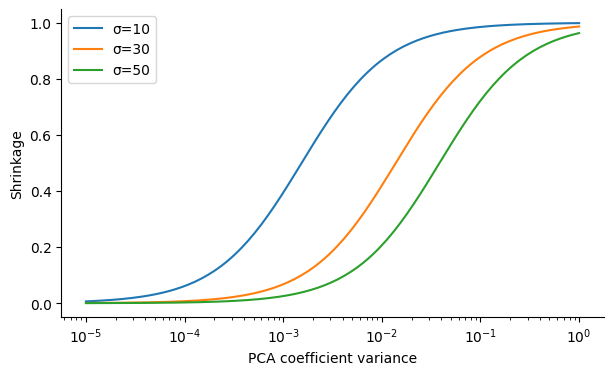

,model,rank,validation_mse
0,pca_projection,16,0.026123
1,pca_projection,32,0.016081
2,pca_projection,64,0.008741
3,pca_projection,128,0.004900
4,pca_wiener,16,0.026187
5,pca_wiener,32,0.016213
6,pca_wiener,64,0.008965
7,pca_wiener,128,0.005154


In [3]:
variances = np.geomspace(1e-5,1,150)
for sigma in [10,30,50]:
    plt.semilogx(variances,variances/(variances+(sigma/255)**2),label=f'σ={sigma}')
plt.xlabel('PCA coefficient variance'); plt.ylabel('Shrinkage'); plt.legend(); plt.show()
pd.DataFrame(m['pca_selection'])

In [4]:
import torch
from learning_lab.restoration import ResidualDenoiser
torch.set_num_threads(2)
net = ResidualDenoiser()
inp = torch.rand(2,2,28,28)
torch.testing.assert_close(net(inp), inp[:,:1])
print('Zero-initialized residual head begins at the observation baseline.')

Zero-initialized residual head begins at the observation baseline.


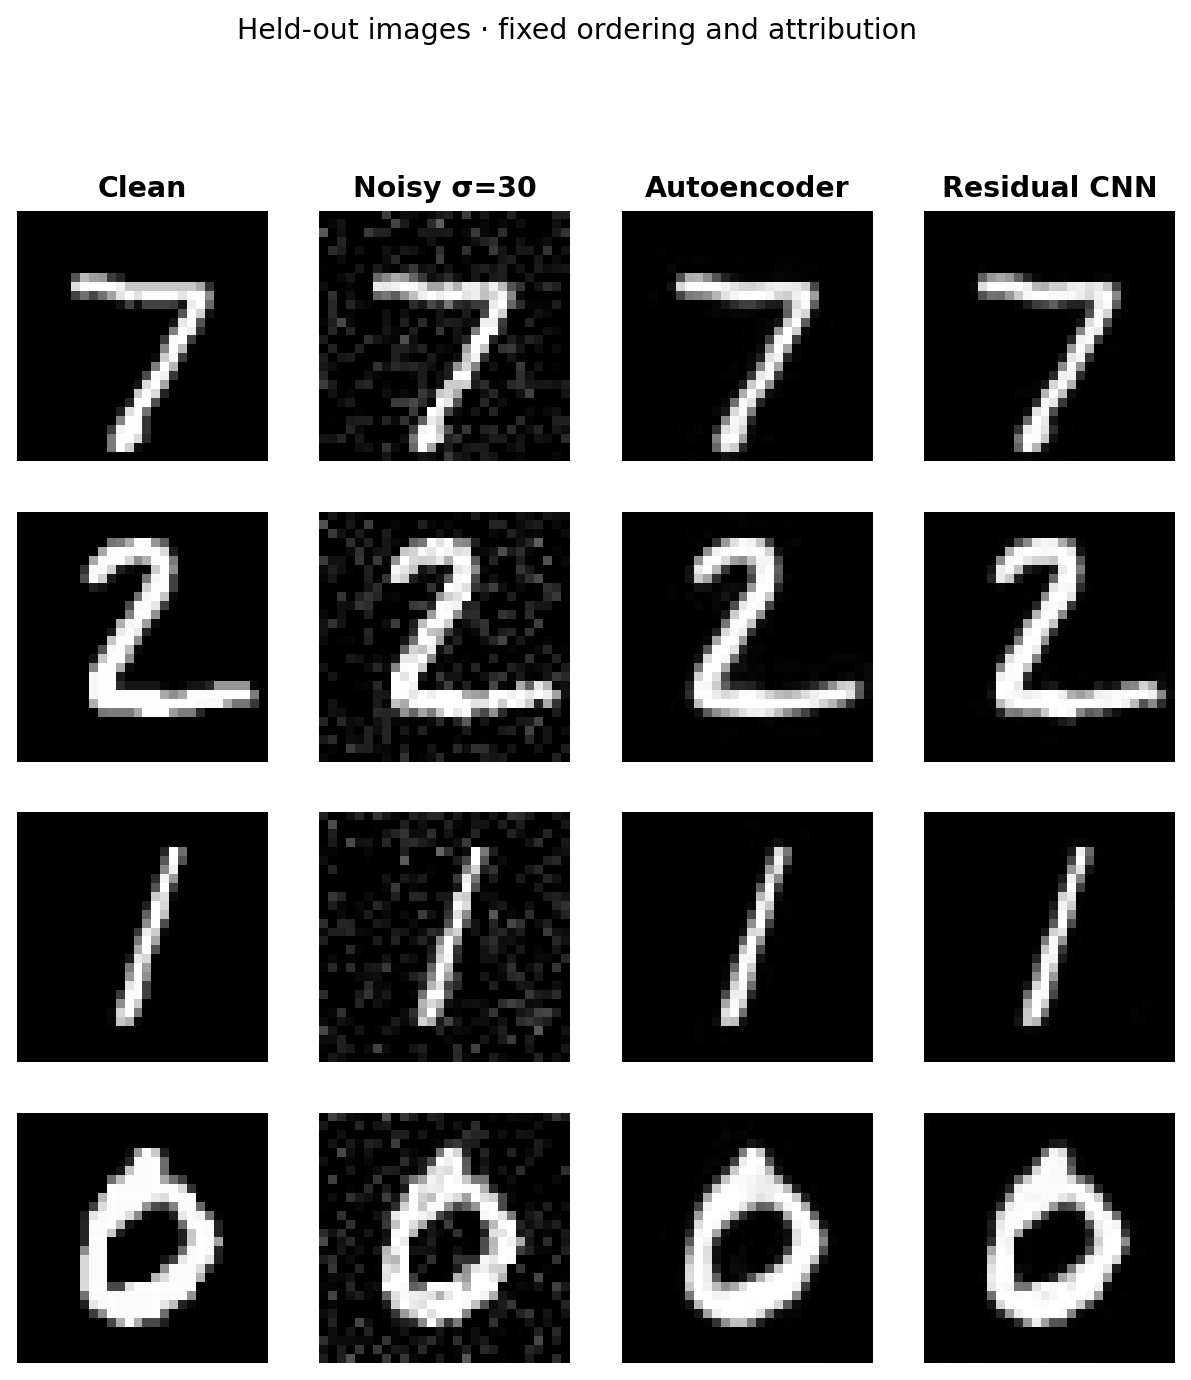

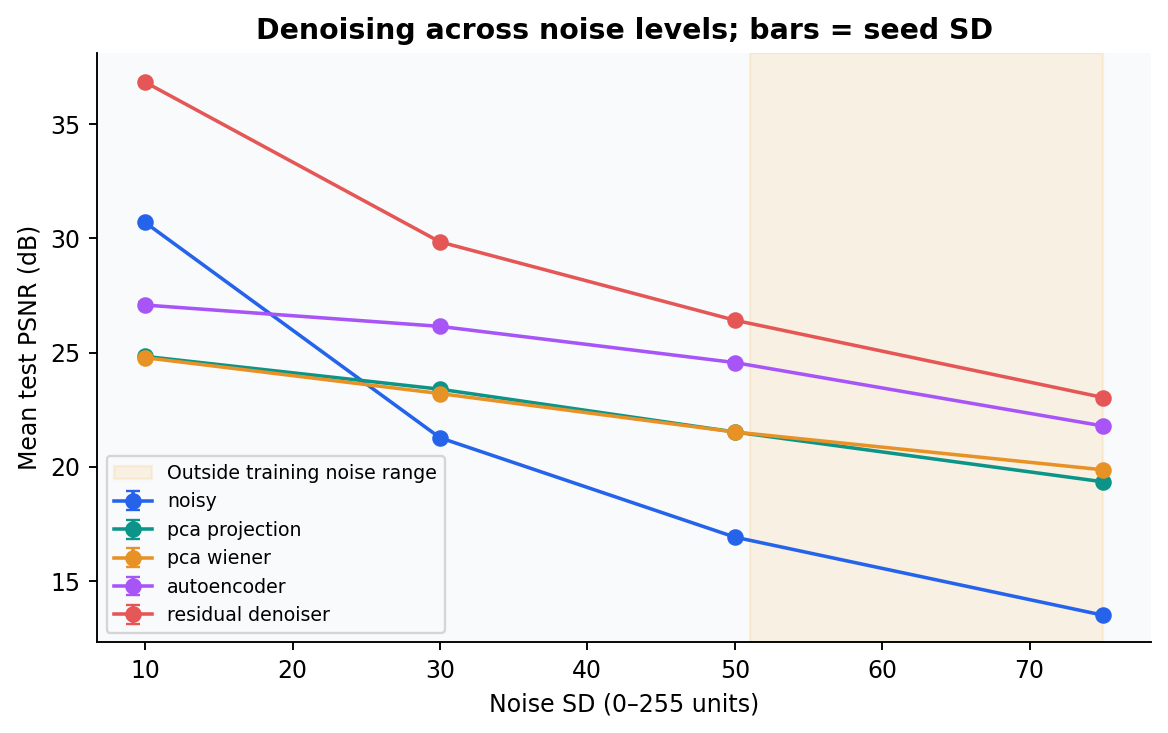

In [5]:
from IPython.display import Image, display
display(Image(filename=str(root/'assets/denoising_gallery.png')))
display(Image(filename=str(root/'assets/denoising_noise_sweep.png')))

## Worked answer
        Why avoid clipping the noisy input in the controlled test? Clipping produces a
        signal-dependent, non-Gaussian observation process near zero and one. Output
        clipping expresses the physical intensity range; it does not repair the noise model.
        The Poisson shift probe makes this assumption visible rather than changing the test
        protocol until every model looks strong.